# UEPNet: end-to-end latency on GPU and CPU

Every pipeline is timed **per frame at batch size 1**, from a decoded 1280x720 frame in RAM to detections on the host:

`preprocess -> UEP -> routing decision -> backbone segment -> detection head -> NMS + box rescaling -> copy to host`

The notebook produces:

1. **Table 1**: inference latency (early exit and final exit) and GFLOPs for YOLOv8m/l/x, plus the UEP on its own.
2. **Table 2 (GPU)** and **Table 3 (CPU)**: end-to-end latency of the full UEPNet system when 0%, 10%, ..., 100% of frames are routed to the early exit, with the saving relative to the final-exit-only baseline.
3. **Figure 1 (GPU)** and **Figure 2 (CPU)**: early-exit rate vs. end-to-end latency saving, one line per model.

### Method
* The baseline (final exit only, no UEP) and UEPNet always run under the **same runtime** on each device, so savings are never inflated by a weaker baseline.
* On GPU, the UEP runs concurrently with the shared prefix (layers 0 to 6). The routing decision is only needed at layer 7.
* The UEP runs on **every** frame (UEP-1), including when the route is forced, so its cost is always paid.
* Two forced-route pipelines are timed: UEP then early exit, and UEP then final exit. For an early-exit rate p, the system latency is `p * T(UEP->early) + (1 - p) * T(UEP->final)`.
* Pipelines are timed **interleaved** (all pipelines on each frame, in rotating order), so clock drift affects all of them equally. Headline numbers are means.


## 1. Setup

In [20]:
# Pre-flight: check GPU + internet first, so nothing hangs silently
import socket, subprocess, sys, importlib.util, torch
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE (Settings -> Accelerator -> GPU T4)')
try:
    socket.create_connection(('pypi.org', 443), timeout=5); print('Internet: OK')
except OSError:
    print('Internet: OFF (Settings -> Internet -> On). pip install and yolov8*.pt downloads will fail.')
if importlib.util.find_spec('ultralytics') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', 'ultralytics==8.4.17', '--timeout', '15', '--retries', '1'], check=True)
import ultralytics; print('ultralytics', ultralytics.__version__)

GPU: Tesla T4
Internet: OK
ultralytics 8.4.17


In [21]:
# ============================ CONFIG ============================
import os

DATA_DIR = '/kaggle/input/datasets/saathvik16/bdd100k-object-dection-with-yolo-format-labels/100k-dataset/test/images'

# --- weights ---
# FINAL: trained full YOLOv8 checkpoints (Ultralytics .pt). COCO 'yolov8m.pt' etc. also work for latency.
# EARLY: trained early-exit checkpoints (.pt or .pth). None -> early-exit YAML with random head weights.
#   Trained early heads are recommended: random heads produce few boxes, so early-path NMS is unrealistically cheap.
W = '/kaggle/input/datasets/saathvik16/yolov8m-weights-trained-early-and-final'
FINAL_WEIGHTS = {'m': 'yolov8m.pt', 'l': 'yolov8l.pt', 'x': 'yolov8x.pt'}
EARLY_WEIGHTS = {'m': None, 'l': None, 'x': None}
UEP_WEIGHTS   = f'{W}/f1_predictor_mobilenet_v3_small.pth'

# --- UEP ---
UEP_INPUT = 224
UEP_MEAN, UEP_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)  # must match UEP training transforms
UEP_APPLY_SIGMOID = True
UEP_TAU = 0.5                # only used if a real-UEP route is added; the tables use forced routes

# --- detector ---
IMGSZ, RECT = 640, True      # 1280x720 -> 640x384 letterbox, as Ultralytics predict does
CONF, IOU, MAX_DET = 0.25, 0.7, 300
SPLIT = 7                    # early and final exits share layers [0, SPLIT)
NC = 10                      # BDD100K classes; both exits are built with nc = 10
GFLOPS_IMGSZ = 640           # GFLOPs reported at 640x640, the standard Ultralytics convention

# --- what to run ---
BACKBONES  = ['m', 'l', 'x']
DEVICES    = ['cuda', 'cpu']
PROFILE    = {'cuda': 'graph_overlap', 'cpu': 'naive'}   # one runtime per device, shared by baseline and UEPNet
EXIT_RATES = list(range(0, 101, 10))                     # % of frames routed to the early exit

N_FRAMES    = {'cuda': 300, 'cpu': 100}
WARMUP      = {'cuda': 30,  'cpu': 3}
CPU_THREADS = None           # None -> torch default

OUT_DIR = '/kaggle/working/latency' if os.path.isdir('/kaggle/working') else './latency'
os.makedirs(OUT_DIR, exist_ok=True)

ALLOW_SMOKE_TEST = False     # True -> synthetic frames if DATA_DIR is missing (numbers NOT reportable)
SMOKE_TEST = not os.path.isdir(DATA_DIR)
if SMOKE_TEST and not ALLOW_SMOKE_TEST:
    raise FileNotFoundError(f'DATA_DIR not found: {DATA_DIR}\nCheck the Kaggle Input panel, or set ALLOW_SMOKE_TEST = True.')
if SMOKE_TEST:
    print('SMOKE TEST: synthetic frames, tiny N. Numbers are NOT reportable.')
    N_FRAMES, WARMUP = {'cuda': 20, 'cpu': 4}, {'cuda': 3, 'cpu': 1}
else:
    print('DATA_DIR OK:', len(os.listdir(DATA_DIR)), 'files')

DATA_DIR OK: 20000 files


In [22]:
import time, glob, json, platform, random, warnings, gc
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import models
from ultralytics import YOLO
from ultralytics.data.augment import LetterBox
from ultralytics.utils import ops
try:
    from ultralytics.utils.nms import non_max_suppression
except ImportError:
    from ultralytics.utils.ops import non_max_suppression

warnings.filterwarnings('ignore')
torch.backends.cudnn.benchmark = True
torch.set_flush_denormal(True)
if CPU_THREADS: torch.set_num_threads(CPU_THREADS)
DEVICES = [d for d in DEVICES if d == 'cpu' or torch.cuda.is_available()]

def cpu_name():
    try: return [l.split(':')[1].strip() for l in open('/proc/cpuinfo') if 'model name' in l][0]
    except Exception: return platform.processor()

ENV = {'torch': torch.__version__, 'cuda': torch.version.cuda, 'cudnn': torch.backends.cudnn.version(),
       'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
       'cpu': cpu_name(), 'cpu_threads': torch.get_num_threads(), 'python': platform.python_version(),
       'ultralytics': ultralytics.__version__}
print(json.dumps(ENV, indent=1)); json.dump(ENV, open(f'{OUT_DIR}/env.json', 'w'), indent=1)
print('Devices:', DEVICES)

{
 "torch": "2.11.0+cu128",
 "cuda": "12.8",
 "cudnn": 91900,
 "gpu": "Tesla T4",
 "cpu": "Intel(R) Xeon(R) CPU @ 2.00GHz",
 "cpu_threads": 2,
 "python": "3.13.15",
 "ultralytics": "8.4.17"
}
Devices: ['cuda', 'cpu']


## 2. Frames
Frames are decoded into RAM in advance, since a camera delivers decoded frames. All frames share one resolution, so the GPU runtime can use static shapes.

In [23]:
def load_frames(n):
    if SMOKE_TEST:
        rng = np.random.default_rng(0)
        return [rng.integers(0, 255, (720, 1280, 3), dtype=np.uint8) for _ in range(n)], float('nan')
    files = sorted(glob.glob(os.path.join(DATA_DIR, '*.jpg')) + glob.glob(os.path.join(DATA_DIR, '*.png')))
    random.Random(0).shuffle(files)
    frames, t = [], []
    for f in files:
        t0 = time.perf_counter(); im = cv2.imread(f); t.append(time.perf_counter() - t0)
        if im is not None and (not frames or im.shape == frames[0].shape):
            frames.append(im)
        if len(frames) == n: break
    return frames, 1e3 * float(np.median(t))

N_MAX = max(N_FRAMES.values()) + max(WARMUP.values())
FRAMES, DECODE_MS = load_frames(N_MAX)
FRAME_SHAPE = FRAMES[0].shape
print(f'{len(FRAMES)} frames of {FRAME_SHAPE}; median JPEG decode {DECODE_MS:.2f} ms (reported, not in E2E)')

330 frames of (720, 1280, 3); median JPEG decode 5.10 ms (reported, not in E2E)


## 3. Models

In [24]:
EARLY_YAML = """nc: {nc}
scales:
  {scale}: {vals}
backbone:
  - [-1, 1, Conv, [64, 3, 2]]
  - [-1, 1, Conv, [128, 3, 2]]
  - [-1, 3, C2f, [128, True]]
  - [-1, 1, Conv, [256, 3, 2]]
  - [-1, 6, C2f, [256, True]]
  - [-1, 1, Conv, [512, 3, 2]]
  - [-1, 6, C2f, [512, True]]      # 6 <- EXIT POINT
head:
  - [-1, 1, Conv, [384, 3, 1]]
  - [-1, 1, Conv, [384, 3, 1]]
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 4], 1, Concat, [1]]
  - [-1, 2, C2f, [256]]
  - [8, 1, Conv, [512, 3, 1]]
  - [[11, 12], 1, Detect, [nc]]
"""
SCALES = {'m': '[0.67, 0.75, 768]', 'l': '[1.00, 1.00, 512]', 'x': '[1.00, 1.25, 512]'}

def load_final(b, verbose=True):
    # The final model is built with nc = NC, so both exits have the same class count.
    # Weights for every layer whose shape matches are copied from FINAL_WEIGHTS; with the COCO
    # checkpoints this is everything except the last class conv of each Detect branch,
    # which keeps its default initialisation (like the early head).
    src = YOLO(FINAL_WEIGHTS[b]).model.float().eval()
    if getattr(src, 'nc', None) == NC:
        return src
    from ultralytics.nn.tasks import DetectionModel
    dm = DetectionModel(f'yolov8{b}.yaml', nc=NC, verbose=False).float().eval()
    tgt, srcsd = dm.state_dict(), src.state_dict()
    keep = {k: v for k, v in srcsd.items() if k in tgt and v.shape == tgt[k].shape}
    dm.load_state_dict(keep, strict=False)
    if verbose:
        print(f'  [yolov8{b}] final model built with nc={NC}: copied {len(keep)}/{len(tgt)} tensors from {FINAL_WEIGHTS[b]}')
    return dm

def load_early(b, final_dm, verbose=True):
    path = EARLY_WEIGHTS.get(b)
    if path and os.path.exists(path) and path.endswith('.pt'):
        dm = YOLO(path).model.float().eval()
    else:
        yml = f'{OUT_DIR}/yolov8{b}_early.yaml'
        open(yml, 'w').write(EARLY_YAML.format(nc=NC, scale=b, vals=SCALES[b]))
        dm = YOLO(yml).model.float().eval()
        if path and os.path.exists(path):
            sd = torch.load(path, map_location='cpu'); sd = sd.get('model', sd)
            sd = sd.state_dict() if hasattr(sd, 'state_dict') else sd
            print('early load:', dm.load_state_dict(sd, strict=False))
        elif verbose:
            print(f'  [yolov8{b}] no early weights -> random head (latency only)')
    diffs = []
    for i in range(SPLIT):
        fs, es = final_dm.model[i].state_dict(), dm.model[i].state_dict()
        assert fs.keys() == es.keys() and all(fs[k].shape == es[k].shape for k in fs), f'layer {i} structure differs'
        diffs.append(max((fs[k].float() - es[k].float()).abs().max().item() for k in fs if fs[k].numel()))
    if max(diffs) > 1e-6:
        if verbose: print(f'  [yolov8{b}] copying final prefix (layers 0-{SPLIT-1}) into early model (exact if backbone was frozen for exit training)')
        for i in range(SPLIT):
            dm.model[i].load_state_dict(final_dm.model[i].state_dict())
    return dm

class UEP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = models.mobilenet_v3_small(weights=None)
        self.net.classifier[-1] = nn.Linear(self.net.classifier[-1].in_features, 1)
    def forward(self, x):
        s = self.net(x).view(-1)
        return torch.sigmoid(s) if UEP_APPLY_SIGMOID else s

def load_uep():
    m = UEP()
    if UEP_WEIGHTS and os.path.exists(UEP_WEIGHTS):
        m.net.load_state_dict(torch.load(UEP_WEIGHTS, map_location='cpu'))
    else:
        print('UEP weights not found -> random init (route=uep decisions are meaningless)')
    return m.eval()

class MultiExit(nn.Module):
    # Shared prefix + two tails, using Ultralytics' own skip-connection semantics.
    def __init__(self, final_dm, early_dm, split=SPLIT):
        super().__init__()
        self.final_dm, self.early_dm, self.split = final_dm, early_dm, split
        self.prefix_layers = final_dm.model[:split]
    @staticmethod
    def _run(layers, x, y):
        for m in layers:
            if m.f != -1:
                x = y[m.f] if isinstance(m.f, int) else [x if j == -1 else y[j] for j in m.f]
            x = m(x); y.append(x)
        return x
    def prefix(self, x):
        y = []; self._run(self.prefix_layers, x, y); return y
    def early_tail(self, y): return self._run(self.early_dm.model[self.split:], y[-1], list(y))
    def final_tail(self, y): return self._run(self.final_dm.model[self.split:], y[-1], list(y))

def first(o): return o[0] if isinstance(o, (tuple, list)) else o

def build(b, dev, prec='fp32', verbose=True):
    fdm = load_final(b, verbose); edm = load_early(b, fdm, verbose)
    fdm.fuse(verbose=False); edm.fuse(verbose=False)
    me = MultiExit(fdm, edm).to(dev).eval(); uep = load_uep().to(dev).eval()
    if prec == 'fp16': me.half(); uep.half()
    return me, uep

## 4. Pre/post-processing and the GPU runtime
* **CPU**: host preprocessing (cv2 letterbox for YOLO, cv2 resize for the UEP) and eager networks.
* **GPU**: the uint8 frame is uploaded once and both inputs are resized on the device. Preprocessing, the full final model, the full early model, the shared prefix, both tails and the UEP are each captured once and replayed. NMS is data-dependent and runs eagerly in every pipeline.

In [25]:
UEP_MEAN_T = torch.tensor(UEP_MEAN).view(1, 3, 1, 1)
UEP_STD_T  = torch.tensor(UEP_STD).view(1, 3, 1, 1)
_LB = LetterBox((IMGSZ, IMGSZ), auto=RECT, stride=32)

def lb_geometry(h, w):
    r = min(IMGSZ / h, IMGSZ / w)
    nw, nh = int(round(w * r)), int(round(h * r))
    dw, dh = IMGSZ - nw, IMGSZ - nh
    if RECT: dw, dh = dw % 32, dh % 32
    top, left = int(round(dh / 2 - 0.1)), int(round(dw / 2 - 0.1))
    return nh, nw, top, dh - top, left, dw - left

def prep_host_yolo(ctx, frame):
    im = _LB(image=frame)[..., ::-1].transpose(2, 0, 1)
    t = torch.from_numpy(np.ascontiguousarray(im)).unsqueeze(0).to(ctx.dev, non_blocking=True)
    return t.to(ctx.dtype) / 255.0

def prep_host_uep(ctx, frame):
    im = cv2.resize(frame, (UEP_INPUT, UEP_INPUT), interpolation=cv2.INTER_LINEAR)[..., ::-1].transpose(2, 0, 1)
    t = torch.from_numpy(np.ascontiguousarray(im)).unsqueeze(0).to(ctx.dev, non_blocking=True)
    return (t.to(ctx.dtype) / 255.0 - ctx.mean) / ctx.std

def _to_float(ctx, fd):   # uint8 HWC BGR on device -> 1x3xHxW RGB [0,1]
    return fd.permute(2, 0, 1).flip(0).unsqueeze(0).to(ctx.dtype) / 255.0

def prep_dev_yolo(ctx, fd):
    nh, nw, top, bot, left, right = lb_geometry(*fd.shape[:2])
    x = F.interpolate(_to_float(ctx, fd), size=(nh, nw), mode='bilinear', align_corners=False)
    return F.pad(x, (left, right, top, bot), value=114 / 255.0)

def prep_dev_uep(ctx, fd):
    x = F.interpolate(_to_float(ctx, fd), size=(UEP_INPUT, UEP_INPUT), mode='bilinear', align_corners=False, antialias=True)
    return (x - ctx.mean) / ctx.std

def postprocess(raw, x_shape, frame_shape):
    det = non_max_suppression(first(raw), CONF, IOU, max_det=MAX_DET)[0]
    if len(det):
        det[:, :4] = ops.scale_boxes(x_shape[2:], det[:, :4], frame_shape)
    return det.float().cpu().numpy()

class Graph:
    # Capture fn() once; __call__ replays it on the current stream and returns the static output.
    def __init__(self, fn, warm=3):
        s = torch.cuda.Stream(); s.wait_stream(torch.cuda.current_stream())
        with torch.cuda.stream(s):
            for _ in range(warm): fn()
        torch.cuda.current_stream().wait_stream(s); torch.cuda.synchronize()
        self.g = torch.cuda.CUDAGraph()
        with torch.cuda.graph(self.g):
            self.out = fn()
        torch.cuda.synchronize()
    def __call__(self):
        self.g.replay(); return self.out

class Ctx:
    def __init__(self, me, uep, device, precision):
        self.me, self.uep, self.dev = me, uep, torch.device(device)
        self.cuda = self.dev.type == 'cuda'
        self.dtype = torch.float16 if precision == 'fp16' else torch.float32
        self.mean = UEP_MEAN_T.to(self.dev, self.dtype); self.std = UEP_STD_T.to(self.dev, self.dtype)
        self.G = None
        if self.cuda:
            self.side = torch.cuda.Stream(); self.ev = torch.cuda.Event()
            self.host_score = torch.empty(1, dtype=torch.float32).pin_memory()

    @torch.inference_mode()
    def capture_graphs(self):
        me, uep = self.me, self.uep
        self.frame_dev = torch.from_numpy(FRAMES[0]).to(self.dev)        # static uint8 input buffer
        G = {}
        G['prep_y'] = Graph(lambda: prep_dev_yolo(self, self.frame_dev)); xy = G['prep_y'].out
        G['prep_u'] = Graph(lambda: prep_dev_uep(self, self.frame_dev));  xu = G['prep_u'].out
        G['full_final'] = Graph(lambda: first(me.final_dm(xy)))
        G['full_early'] = Graph(lambda: first(me.early_dm(xy)))
        G['prefix'] = Graph(lambda: me.prefix(xy)); ypre = G['prefix'].out
        G['early_tail'] = Graph(lambda: first(me.early_tail(ypre)))
        G['final_tail'] = Graph(lambda: first(me.final_tail(ypre)))
        G['uep'] = Graph(lambda: uep(xu).float().view(-1))
        self.G = G

    @torch.inference_mode()
    def verify_graphs(self):
        # Graph replay must reproduce eager execution of the same inputs.
        me, G = self.me, self.G
        self.frame_dev.copy_(torch.from_numpy(FRAMES[1]))
        xy = prep_dev_yolo(self, self.frame_dev); xu = prep_dev_uep(self, self.frame_dev)
        ref_f, ref_e, ref_u = first(me.final_dm(xy)).float(), first(me.early_dm(xy)).float(), self.uep(xu).float()
        G['prep_y'](); G['prep_u']()
        def rel(a, b): return ((a.float() - b).abs().max() / (b.abs().max() + 1e-6)).item()
        r = {'full_final': rel(G['full_final'](), ref_f), 'full_early': rel(G['full_early'](), ref_e),
             'uep': rel(G['uep'](), ref_u)}
        G['prefix'](); r['prefix+final_tail'] = rel(G['final_tail'](), ref_f); r['prefix+early_tail'] = rel(G['early_tail'](), ref_e)
        tol = 2e-2 if self.dtype == torch.float16 else 1e-3
        ok = all(v < tol for v in r.values())
        print('  graph vs eager (max rel. diff):', {k: f'{v:.1e}' for k, v in r.items()}, 'OK' if ok else 'MISMATCH')
        assert ok, 'CUDA graph replay does not reproduce eager outputs'
        return r

## 5. Pipelines and interleaved timing harness

In [26]:
def sync(ctx):
    if ctx.cuda: torch.cuda.synchronize()

def decide(route, score, rng):
    if route == 'early': return True
    if route == 'final': return False
    if route == 'uep':   return score >= UEP_TAU
    return rng.random() < float(route)

@torch.inference_mode()
def step_eager(ctx, frame, pipe, route, refresh, state, rng, m):
    # 'naive': host preprocessing, eager networks, UEP -> decision -> backbone.
    me = ctx.me
    need_uep = pipe == 'uep' and refresh
    xy = prep_host_yolo(ctx, frame); xu = prep_host_uep(ctx, frame) if need_uep else None; m('preprocess')
    if pipe == 'final_only':
        raw = me.final_dm(xy); m('backbone+head'); return postprocess(raw, xy.shape, frame.shape), False
    if pipe == 'early_only':
        raw = me.early_dm(xy); m('backbone+head'); return postprocess(raw, xy.shape, frame.shape), True
    if need_uep:
        score = ctx.uep(xu).float().item(); m('uep')
        early = decide(route, score, rng); state['early'] = early
    else:
        early = state['early']
    y = me.prefix(xy); m('prefix')
    raw = me.early_tail(y) if early else me.final_tail(y); m('tail+head')
    out = postprocess(raw, xy.shape, frame.shape); m('nms+copy')
    return out, early

@torch.inference_mode()
def step_graph(ctx, frame, pipe, route, refresh, state, rng, m, overlap):
    # 'graph_seq' / 'graph_overlap': one upload, everything replayed from CUDA graphs.
    G = ctx.G
    ctx.frame_dev.copy_(torch.from_numpy(frame))                     # H2D upload of the raw frame
    xs = G['prep_y'].out.shape
    need_uep = pipe == 'uep' and refresh
    if pipe in ('final_only', 'early_only'):
        G['prep_y'](); m('preprocess')
        raw = G['full_final']() if pipe == 'final_only' else G['full_early'](); m('backbone+head')
        return postprocess(raw, xs, frame.shape), pipe == 'early_only'
    if not need_uep:                                                  # stride-k: held decision
        G['prep_y'](); m('preprocess'); G['prefix'](); m('prefix'); early = state['early']
    elif not overlap:
        G['prep_y'](); G['prep_u'](); m('preprocess')
        score = G['uep']().item(); m('uep')
        early = decide(route, score, rng); state['early'] = early
        G['prefix'](); m('prefix')
    else:                                                             # UEP on side stream || prefix on main
        main = torch.cuda.current_stream()
        ctx.side.wait_stream(main)
        with torch.cuda.stream(ctx.side):
            G['prep_u'](); s = G['uep']()
            ctx.host_score.copy_(s[:1], non_blocking=True); ctx.ev.record(ctx.side)
        G['prep_y'](); G['prefix']()
        ctx.ev.synchronize()                                          # host waits for the UEP only
        early = decide(route, ctx.host_score.item(), rng); state['early'] = early; m('uep||prefix')
    raw = G['early_tail']() if early else G['final_tail'](); m('tail+head')
    out = postprocess(raw, xs, frame.shape); m('nms+copy')
    return out, early

def step(ctx, frame, prof, pipe, route, refresh, state, rng, marks=None):
    m = (lambda s: (sync(ctx), marks.append((s, time.perf_counter())))) if marks is not None else (lambda s: None)
    if marks is not None: m('start')
    if prof == 'naive':
        return step_eager(ctx, frame, pipe, route, refresh, state, rng, m)
    return step_graph(ctx, frame, pipe, route, refresh, state, rng, m, overlap=(prof == 'graph_overlap'))

def bench_interleaved(ctx, jobs, n, warm):
    # Every frame, run all jobs in a rotating order, so drift hits every pipeline equally.
    # job = (profile, pipeline, route, k)
    S = {j: dict(state={'early': False}, rng=random.Random(1234), lat=[], ef=[]) for j in jobs}
    J = len(jobs)
    for t in range(warm + n):
        frame = FRAMES[t % len(FRAMES)]
        for idx in range(J):
            j = jobs[(idx + t) % J]; prof, pipe, route, k = j; s = S[j]
            sync(ctx); t0 = time.perf_counter()
            _, early = step(ctx, frame, prof, pipe, route, t % k == 0, s['state'], s['rng'])
            sync(ctx); dt = 1e3 * (time.perf_counter() - t0)
            if t >= warm: s['lat'].append(dt); s['ef'].append(early)
    return {j: (np.array(v['lat']), np.array(v['ef'])) for j, v in S.items()}

def breakdown(ctx, prof, route, n, warm):
    rows, state, rng = [], {'early': False}, random.Random(0)
    for t in range(warm + n):
        marks = []
        step(ctx, FRAMES[t % len(FRAMES)], prof, 'uep', route, True, state, rng, marks)
        if t >= warm: rows.append({s: 1e3 * (b - a) for (_, a), (s, b) in zip(marks[:-1], marks[1:])})
    return pd.DataFrame(rows).median().to_dict()

def stats(lat):
    return dict(mean=lat.mean(), ci95=1.96 * lat.std(ddof=1) / np.sqrt(len(lat)) if len(lat) > 1 else np.nan,
                median=np.median(lat), p95=np.percentile(lat, 95), p99=np.percentile(lat, 99))

## 6. Sanity checks
1. Segmented execution (prefix + tail) reproduces the full models exactly.
2. GPU replay reproduces eager outputs.
3. The UEP alone is timed on each device (used in Table 1).

In [27]:
CHECKS = {}
def timeit(ctx, fn, reps):
    for _ in range(10): fn()
    sync(ctx); ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); sync(ctx); ts.append(1e3 * (time.perf_counter() - t0))
    return float(np.mean(ts))

for dev in DEVICES:
    print(f'== {dev} ==')
    me, uep = build('m', dev)
    with torch.inference_mode():
        x = torch.rand(1, 3, 384, 640, device=dev); y = me.prefix(x)
        e = (first(me.early_tail(y)) - first(me.early_dm(x))).abs().max().item()
        f = (first(me.final_tail(y)) - first(me.final_dm(x))).abs().max().item()
    print(f'  segmented vs full: early {e:.1e}, final {f:.1e}'); assert e < 1e-3 and f < 1e-3

    ctx = Ctx(me, uep, dev, 'fp32')
    if dev == 'cuda':
        ctx.capture_graphs(); CHECKS['graph_check'] = ctx.verify_graphs()
        CHECKS['uep_ms_cuda'] = timeit(ctx, lambda: ctx.G['uep'](), 300)       # UEP as run in the GPU pipeline
    else:
        xu = torch.randn(1, 3, UEP_INPUT, UEP_INPUT)
        with torch.inference_mode():
            CHECKS['uep_ms_cpu'] = timeit(ctx, lambda: uep(xu), 100)
    print(f"  UEP alone: {CHECKS[f'uep_ms_{dev}']:.2f} ms")
    del me, uep, ctx; gc.collect()
    if dev == 'cuda': torch.cuda.empty_cache()
json.dump(CHECKS, open(f'{OUT_DIR}/checks.json', 'w'), indent=1, default=str)

== cuda ==
Overriding model.yaml nc=80 with nc=10
  [yolov8m] final model built with nc=10: copied 469/475 tensors from yolov8m.pt
  [yolov8m] no early weights -> random head (latency only)
  [yolov8m] copying final prefix (layers 0-6) into early model (exact if backbone was frozen for exit training)
  segmented vs full: early 0.0e+00, final 0.0e+00
  graph vs eager (max rel. diff): {'full_final': '0.0e+00', 'full_early': '0.0e+00', 'uep': '0.0e+00', 'prefix+final_tail': '0.0e+00', 'prefix+early_tail': '0.0e+00'} OK
  UEP alone: 0.75 ms
== cpu ==
Overriding model.yaml nc=80 with nc=10
  [yolov8m] final model built with nc=10: copied 469/475 tensors from yolov8m.pt
  [yolov8m] no early weights -> random head (latency only)
  [yolov8m] copying final prefix (layers 0-6) into early model (exact if backbone was frozen for exit training)
  segmented vs full: early 0.0e+00, final 0.0e+00
  UEP alone: 10.72 ms


## 7. GFLOPs
One convention for every row: **FLOPs = 2 x MACs**, as Ultralytics reports YOLO GFLOPs (YOLOv8m = 78.9 at 640x640 with 80 classes). Detectors are measured at 640x640 with nc = 10, unfused. The UEP is measured the same way at its 224x224 input, so it reads about twice its MAC count.

In [28]:
import thop
from copy import deepcopy

def gflops(model, shape):
    macs, _ = thop.profile(deepcopy(model).cpu().float().eval(), inputs=(torch.zeros(shape),), verbose=False)
    return 2 * macs / 1e9

GFLOPS = {}
for b in BACKBONES:
    fdm = load_final(b, verbose=False); edm = load_early(b, fdm, verbose=False)
    GFLOPS[b] = {'early': gflops(edm, (1, 3, GFLOPS_IMGSZ, GFLOPS_IMGSZ)),
                 'final': gflops(fdm, (1, 3, GFLOPS_IMGSZ, GFLOPS_IMGSZ))}
    print(f"YOLOv8{b}: early {GFLOPS[b]['early']:.1f}, final {GFLOPS[b]['final']:.1f} GFLOPs")
    del fdm, edm; gc.collect()
GFLOPS['uep'] = gflops(load_uep(), (1, 3, UEP_INPUT, UEP_INPUT))
print(f"UEP: {GFLOPS['uep']:.3f} GFLOPs")

Overriding model.yaml nc=80 with nc=10
YOLOv8m: early 60.6, final 79.1 GFLOPs
Overriding model.yaml nc=80 with nc=10
YOLOv8l: early 131.3, final 165.4 GFLOPs
Overriding model.yaml nc=80 with nc=10
YOLOv8x: early 204.9, final 258.2 GFLOPs
UEP: 0.123 GFLOPs


## 8. Main benchmark
For each device and backbone, four pipelines are timed interleaved on the same frames:
final exit only, early exit only, UEP then early exit, UEP then final exit.
Expect roughly 5 minutes on GPU and 20 minutes on CPU.

In [29]:
ROWS = []
for dev in DEVICES:
    prof = PROFILE[dev]
    for b in BACKBONES:
        me, uep = build(b, dev)
        ctx = Ctx(me, uep, dev, 'fp32')
        if prof.startswith('graph'):
            ctx.capture_graphs(); ctx.verify_graphs()
        jobs = [(prof, 'final_only', 'final', 1), (prof, 'early_only', 'early', 1),
                (prof, 'uep', 'early', 1), (prof, 'uep', 'final', 1)]
        t0 = time.time()
        res = bench_interleaved(ctx, jobs, N_FRAMES[dev], WARMUP[dev])
        for (_, pipe, route, _), (lat, ef) in res.items():
            ROWS.append(dict(device=dev, backbone=b, pipeline=pipe, route=route, n=len(lat), **stats(lat)))
        print(f'{dev} yolov8{b}: {len(jobs)} pipelines x {N_FRAMES[dev]} frames in {time.time()-t0:.0f}s')
        del me, uep, ctx; gc.collect()
        if dev == 'cuda': torch.cuda.empty_cache()

RES = pd.DataFrame(ROWS)
RES.to_csv(f'{OUT_DIR}/latency_raw.csv', index=False)

def T(dev, b, pipe, route):
    q = RES[(RES.device == dev) & (RES.backbone == b) & (RES.pipeline == pipe) & (RES.route == route)]
    return float(q['mean'].iloc[0])

# Mean latency (ms) per device and backbone
LAT = {dev: {b: dict(final=T(dev, b, 'final_only', 'final'), early=T(dev, b, 'early_only', 'early'),
                     uep_e=T(dev, b, 'uep', 'early'), uep_f=T(dev, b, 'uep', 'final'))
             for b in BACKBONES} for dev in DEVICES}
json.dump(LAT, open(f'{OUT_DIR}/latency_means.json', 'w'), indent=1)

Overriding model.yaml nc=80 with nc=10
  [yolov8m] final model built with nc=10: copied 469/475 tensors from yolov8m.pt
  [yolov8m] no early weights -> random head (latency only)
  [yolov8m] copying final prefix (layers 0-6) into early model (exact if backbone was frozen for exit training)
  graph vs eager (max rel. diff): {'full_final': '0.0e+00', 'full_early': '0.0e+00', 'uep': '0.0e+00', 'prefix+final_tail': '0.0e+00', 'prefix+early_tail': '0.0e+00'} OK
cuda yolov8m: 4 pipelines x 300 frames in 20s
Overriding model.yaml nc=80 with nc=10
  [yolov8l] final model built with nc=10: copied 589/595 tensors from yolov8l.pt
  [yolov8l] no early weights -> random head (latency only)
  [yolov8l] copying final prefix (layers 0-6) into early model (exact if backbone was frozen for exit training)
  graph vs eager (max rel. diff): {'full_final': '0.0e+00', 'full_early': '0.0e+00', 'uep': '0.0e+00', 'prefix+final_tail': '0.0e+00', 'prefix+early_tail': '0.0e+00'} OK
cuda yolov8l: 4 pipelines x 300 

## 9. Tables

In [30]:
from IPython.display import display
pd.set_option('display.width', 200)
DEV_NAME = {'cuda': 'GPU', 'cpu': 'CPU'}
MINUS = '\u2212'   # typographic minus sign, so negative savings read clearly

def fmt_saving(s):
    return f'{MINUS}{abs(s):.1f}%' if s < 0 else f'+{s:.1f}%'

# ---------- Table 1: inference latency and GFLOPs ----------
cols = pd.MultiIndex.from_tuples([('GPU Time (ms)', 'Early'), ('GPU Time (ms)', 'Final'),
                                  ('CPU Time (ms)', 'Early'), ('CPU Time (ms)', 'Final'),
                                  ('GFLOPs', 'Early'), ('GFLOPs', 'Final')])
rows, idx = [], []
for b in BACKBONES:
    idx.append(f'YOLOv8{b}')
    rows.append([f"{LAT['cuda'][b]['early']:.1f}", f"{LAT['cuda'][b]['final']:.1f}",
                 f"{LAT['cpu'][b]['early']:.1f}",  f"{LAT['cpu'][b]['final']:.1f}",
                 f"{GFLOPS[b]['early']:.1f}",      f"{GFLOPS[b]['final']:.1f}"])
idx.append('UEP alone')
rows.append([f"{CHECKS['uep_ms_cuda']:.2f}", '', f"{CHECKS['uep_ms_cpu']:.2f}", '', f"{GFLOPS['uep']:.2f}", ''])
TABLE1 = pd.DataFrame(rows, index=pd.Index(idx, name='Model'), columns=cols)
print('Table 1: Inference latency and GFLOPs')
display(TABLE1)
TABLE1.to_csv(f'{OUT_DIR}/table1_latency_gflops.csv')

# ---------- Tables 2 and 3: end-to-end latency vs early-exit rate ----------
def e2e_latency(dev, b, p):
    L = LAT[dev][b]
    return p / 100 * L['uep_e'] + (1 - p / 100) * L['uep_f']

def e2e_saving(dev, b, p):
    return 100 * (LAT[dev][b]['final'] - e2e_latency(dev, b, p)) / LAT[dev][b]['final']

E2E = {}
for dev in DEVICES:
    idx = ['Final-only baseline (no UEP)'] + [f'{p}%' for p in EXIT_RATES]
    data = {f'YOLOv8{b}': [f"{LAT[dev][b]['final']:.1f}"] +
                          [f'{e2e_latency(dev, b, p):.1f} ({fmt_saving(e2e_saving(dev, b, p))})' for p in EXIT_RATES]
            for b in BACKBONES}
    E2E[dev] = pd.DataFrame(data, index=pd.Index(idx, name='% early'))
    print(f'\n{DEV_NAME[dev]} End to End Latencies (ms, saving vs final-only baseline)')
    display(E2E[dev])
    E2E[dev].to_csv(f'{OUT_DIR}/table_e2e_{DEV_NAME[dev].lower()}.csv')

    be = ', '.join(f"YOLOv8{b} {100*(LAT[dev][b]['uep_f']-LAT[dev][b]['final'])/(LAT[dev][b]['uep_f']-LAT[dev][b]['uep_e']):.1f}%"
                   for b in BACKBONES)
    print(f'Break-even early-exit rate: {be}')

Table 1: Inference latency and GFLOPs


GPU Time (ms)       CPU Time (ms)        GFLOPs       
                  Early Final         Early  Final  Early  Final
Model                                                           
YOLOv8m            12.0  17.5         204.4  286.0   60.6   79.1
YOLOv8l            20.0  27.9         408.4  535.4  131.3  165.4
YOLOv8x            32.9  45.0         632.2  823.0  204.9  258.2
UEP alone          0.75               10.72          0.12


GPU End to End Latencies (ms, saving vs final-only baseline)


,YOLOv8m,YOLOv8l,YOLOv8x
% early,,,
Final-only baseline (no UEP),17.5,27.9,45.0
0%,18.3 (−4.5%),28.9 (−3.7%),46.3 (−2.9%)
10%,17.8 (−1.3%),28.1 (−0.9%),45.1 (−0.1%)
20%,17.2 (+1.9%),27.3 (+2.0%),43.9 (+2.6%)
30%,16.7 (+5.0%),26.5 (+4.8%),42.6 (+5.4%)
40%,16.1 (+8.2%),25.7 (+7.7%),41.4 (+8.1%)
50%,15.5 (+11.3%),24.9 (+10.5%),40.2 (+10.8%)
60%,15.0 (+14.5%),24.1 (+13.4%),38.9 (+13.6%)
70%,14.4 (+17.7%),23.3 (+16.2%),37.7 (+16.3%)


Break-even early-exit rate: YOLOv8m 14.1%, YOLOv8l 13.1%, YOLOv8x 10.4%

CPU End to End Latencies (ms, saving vs final-only baseline)


,YOLOv8m,YOLOv8l,YOLOv8x
% early,,,
Final-only baseline (no UEP),286.0,535.4,823.0
0%,300.9 (−5.2%),548.0 (−2.4%),834.9 (−1.4%)
10%,292.7 (−2.3%),535.2 (+0.0%),815.8 (+0.9%)
20%,284.5 (+0.5%),522.5 (+2.4%),796.7 (+3.2%)
30%,276.3 (+3.4%),509.7 (+4.8%),777.6 (+5.5%)
40%,268.1 (+6.3%),496.9 (+7.2%),758.5 (+7.8%)
50%,259.9 (+9.1%),484.1 (+9.6%),739.4 (+10.2%)
60%,251.7 (+12.0%),471.3 (+12.0%),720.4 (+12.5%)
70%,243.5 (+14.8%),458.5 (+14.4%),701.3 (+14.8%)


Break-even early-exit rate: YOLOv8m 18.2%, YOLOv8l 9.9%, YOLOv8x 6.2%


In [31]:
# LaTeX versions of the three tables
def latex_table1():
    s = [r'\begin{tabular}{lcccccc}', r'\toprule',
         r'\multirow{2}{*}{\textbf{Model}} & \multicolumn{2}{c}{\textbf{GPU Time (ms)}} & \multicolumn{2}{c}{\textbf{CPU Time (ms)}} & \multicolumn{2}{c}{\textbf{GFLOPs}} \\',
         r'\cmidrule(lr){2-3}\cmidrule(lr){4-5}\cmidrule(lr){6-7}',
         r' & Early & Final & Early & Final & Early & Final \\', r'\midrule']
    for b in BACKBONES:
        s.append(f"\\textbf{{YOLOv8{b}}} & {LAT['cuda'][b]['early']:.1f} & {LAT['cuda'][b]['final']:.1f} & "
                 f"{LAT['cpu'][b]['early']:.1f} & {LAT['cpu'][b]['final']:.1f} & "
                 f"{GFLOPS[b]['early']:.1f} & {GFLOPS[b]['final']:.1f} \\\\")
    s += [r'\midrule',
          f"\\textbf{{UEP}} & \\multicolumn{{2}}{{c}}{{{CHECKS['uep_ms_cuda']:.2f}}} & "
          f"\\multicolumn{{2}}{{c}}{{{CHECKS['uep_ms_cpu']:.2f}}} & \\multicolumn{{2}}{{c}}{{{GFLOPS['uep']:.2f}}} \\\\",
          r'\bottomrule', r'\end{tabular}']
    return '\n'.join(s)

def latex_e2e(dev):
    def cell(b, p):
        s = e2e_saving(dev, b, p)
        sign = '$-$' if s < 0 else '+'
        return f'{e2e_latency(dev, b, p):.1f} ({sign}{abs(s):.1f}\\%)'
    s = [r'\begin{tabular}{lccc}', r'\toprule',
         r'\textbf{\% early} & ' + ' & '.join(f'\\textbf{{YOLOv8{b}}}' for b in BACKBONES) + r' \\', r'\midrule',
         'Final-only baseline (no UEP) & ' + ' & '.join(f"{LAT[dev][b]['final']:.1f}" for b in BACKBONES) + r' \\', r'\midrule']
    for p in EXIT_RATES:
        s.append(f'{p}\\% & ' + ' & '.join(cell(b, p) for b in BACKBONES) + r' \\')
    s += [r'\bottomrule', r'\end{tabular}']
    return '\n'.join(s)

print('% Table 1: Inference latency and GFLOPs\n' + latex_table1())
for dev in DEVICES:
    print(f'\n% {DEV_NAME[dev]} End to End Latencies\n' + latex_e2e(dev))

% Table 1: Inference latency and GFLOPs
\begin{tabular}{lcccccc}
\toprule
\multirow{2}{*}{\textbf{Model}} & \multicolumn{2}{c}{\textbf{GPU Time (ms)}} & \multicolumn{2}{c}{\textbf{CPU Time (ms)}} & \multicolumn{2}{c}{\textbf{GFLOPs}} \\
\cmidrule(lr){2-3}\cmidrule(lr){4-5}\cmidrule(lr){6-7}
 & Early & Final & Early & Final & Early & Final \\
\midrule
\textbf{YOLOv8m} & 12.0 & 17.5 & 204.4 & 286.0 & 60.6 & 79.1 \\
\textbf{YOLOv8l} & 20.0 & 27.9 & 408.4 & 535.4 & 131.3 & 165.4 \\
\textbf{YOLOv8x} & 32.9 & 45.0 & 632.2 & 823.0 & 204.9 & 258.2 \\
\midrule
\textbf{UEP} & \multicolumn{2}{c}{0.75} & \multicolumn{2}{c}{10.72} & \multicolumn{2}{c}{0.12} \\
\bottomrule
\end{tabular}

% GPU End to End Latencies
\begin{tabular}{lccc}
\toprule
\textbf{\% early} & \textbf{YOLOv8m} & \textbf{YOLOv8l} & \textbf{YOLOv8x} \\
\midrule
Final-only baseline (no UEP) & 17.5 & 27.9 & 45.0 \\
\midrule
0\% & 18.3 ($-$4.5\%) & 28.9 ($-$3.7\%) & 46.3 ($-$2.9\%) \\
10\% & 17.8 ($-$1.3\%) & 28.1 ($-$0.9\%) & 45.1 (

## 10. Figures

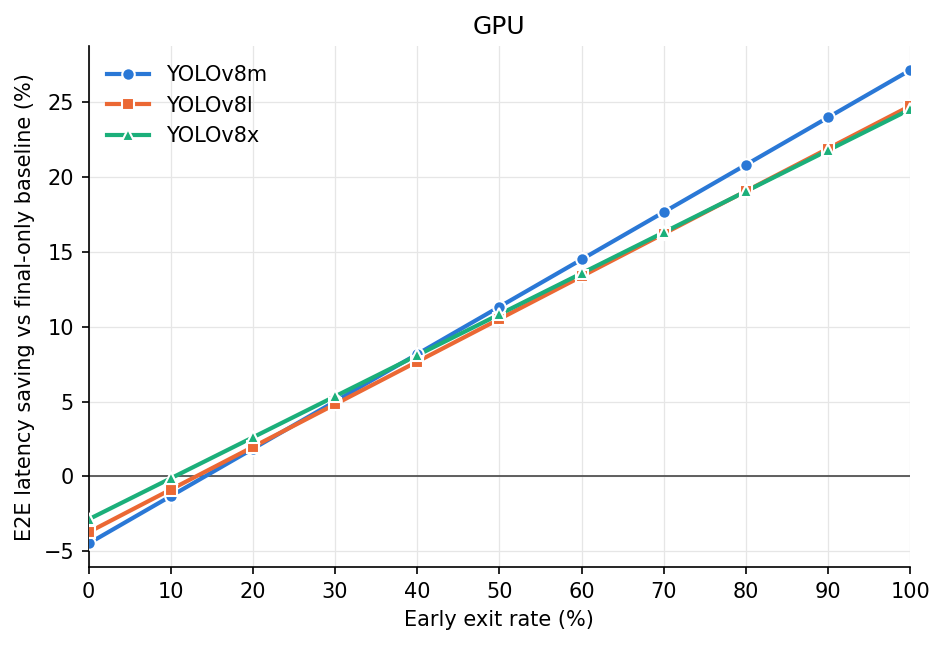

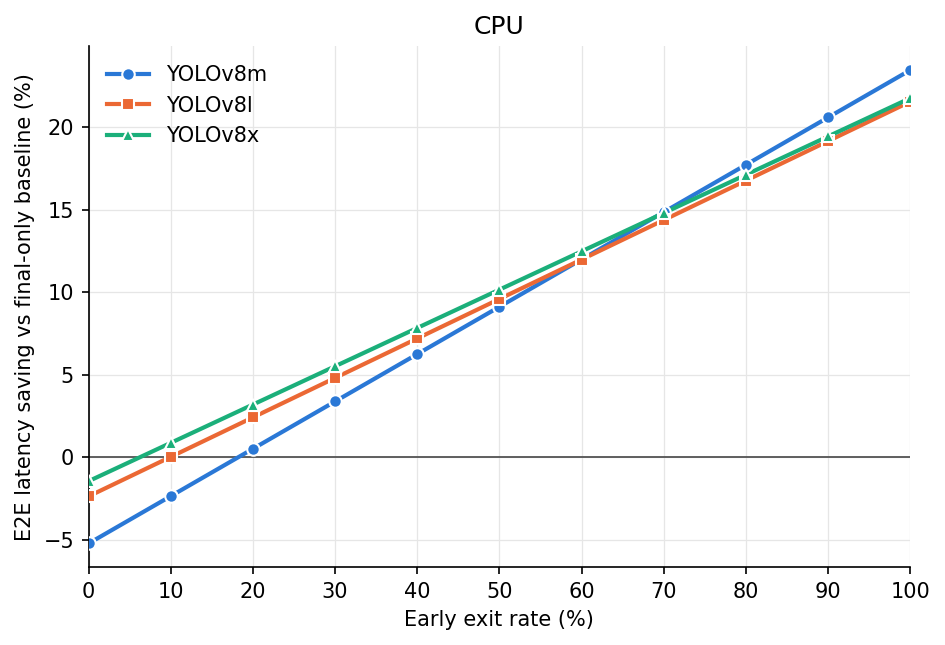

In [32]:
MODEL_STYLE = {'m': ('#2a78d6', 'o'), 'l': ('#eb6834', 's'), 'x': ('#1baf7a', '^')}
p_dense = np.linspace(0, 100, 201)

def fig_e2e(dev):
  with plt.style.context('default'):   # default font and style
      fig, ax = plt.subplots(figsize=(6.4, 4.4), dpi=150)
      ax.axhline(0, color='0.35', lw=0.9, zorder=1)
      for b in BACKBONES:
          c, mk = MODEL_STYLE[b]
          ax.plot(p_dense, [e2e_saving(dev, b, p) for p in p_dense], color=c, lw=2, zorder=2)
          ax.plot(EXIT_RATES, [e2e_saving(dev, b, p) for p in EXIT_RATES], ls='none', marker=mk, ms=6,
                  color=c, markeredgecolor='white', markeredgewidth=1, zorder=3)
          ax.plot([], [], color=c, lw=2, marker=mk, ms=6, markeredgecolor='white', label=f'YOLOv8{b}')
      ax.set_xlim(0, 100); ax.set_xticks(EXIT_RATES)
      ax.set_xlabel('Early exit rate (%)')
      ax.set_ylabel('E2E latency saving vs final-only baseline (%)')
      ax.set_title(DEV_NAME[dev])
      ax.grid(True, color='0.9', lw=0.6); ax.set_axisbelow(True)
      for s in ('top', 'right'): ax.spines[s].set_visible(False)
      ax.legend(frameon=False, loc='upper left')
      fig.tight_layout()
      fig.savefig(f'{OUT_DIR}/fig_e2e_saving_{DEV_NAME[dev].lower()}.png', bbox_inches='tight')
      fig.savefig(f'{OUT_DIR}/fig_e2e_saving_{DEV_NAME[dev].lower()}.pdf', bbox_inches='tight')
      plt.show()

for dev in DEVICES:
    fig_e2e(dev)